# CDS4003 – Credit Card Fraud Detection
## Combined Notebook: Stages 4, 5 and 6

This notebook combines the project's feature preparation/EDA work, model selection and development, and hyperparameter tuning/evaluation.

### Before running
1. Keep the original dataset file **`creditcard.csv`** in the same folder as this notebook.
2. Install the packages listed in `requirements_combined.txt`.
3. Run the notebook from the first cell to the last cell, in order.

**Important:** Stage 4 creates `creditcard_clean.csv` and `creditcard_features.csv`. Stages 5 and 6 use `creditcard_features.csv`, so do not skip the Stage 4 feature-engineering cell.

The notebook preserves the project's chronological 80/20 split and time-series validation workflow. Test-set results are for final evaluation only.


# Stage 4 – Data Preparation, Exploratory Data Analysis and Feature Engineering

The following cells contain the project's cleaning, exploratory analysis and feature-engineering workflow. They create the feature-engineered dataset required by Stages 5 and 6.



=== DATA UNDERSTANDING ===
Shape: (284807, 31)
Columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Summary Statistics:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000



=== DATA TYPES ===
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


=== BEFORE CLEANING ===
Shape: (284807, 31)
Missing Values: 0
Duplicates: 1081

=== INVALID VALUES ===
Negative Amount: 0
Negative Time: 0
Invalid Class: 0

=== AFTER CLEANING ===
Shape: (283726, 31)
Missing Values: 0
Duplicates: 0

=== OUTLIERS ===
Amount Outliers: 31685
Fraud Among Outliers: 87


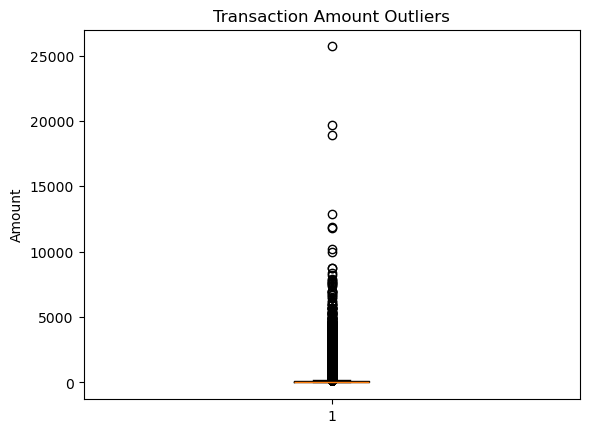

Cleaned dataset saved!


In [18]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("creditcard.csv")

print("\n=== DATA UNDERSTANDING ===")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

print("\nSummary Statistics:")
display(df.describe())

print("\n=== DATA TYPES ===")
print(df.dtypes)

display(df.head())

print("=== BEFORE CLEANING ===")
print("Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

print("\n=== INVALID VALUES ===")
print("Negative Amount:", (df["Amount"] < 0).sum())
print("Negative Time:", (df["Time"] < 0).sum())
print("Invalid Class:", (~df["Class"].isin([0, 1])).sum())

df = df.dropna()
df = df.drop_duplicates()
df = df[(df["Amount"] >= 0) & (df["Time"] >= 0)]
df = df[df["Class"].isin([0, 1])]


print("\n=== AFTER CLEANING ===")
print("Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

Q1 = df["Amount"].quantile(0.25)
Q3 = df["Amount"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df["Amount"] < lower) | (df["Amount"] > upper)]

print("\n=== OUTLIERS ===")
print("Amount Outliers:", len(outliers))
print("Fraud Among Outliers:", (outliers["Class"] == 1).sum())



plt.boxplot(df["Amount"])
plt.title("Transaction Amount Outliers")
plt.ylabel("Amount")
plt.show()

df.to_csv("creditcard_clean.csv", index=False)
print("Cleaned dataset saved!")


## Data Understanding
The dataset contains 284,807 transactions and 31 columns.
The target variable is Class (0 = Normal, 1 = Fraud).

## Data Cleaning
The dataset had no missing or invalid values.
We removed 1,081 exact duplicate rows.
After cleaning, 283,726 transactions remained.

## Outlier Detection
We used the IQR method to detect unusual transaction amounts.
We found 31,685 Amount outliers, including 87 fraudulent transactions.
We kept the outliers because they may contain useful fraud patterns.

## Data Limitations
The dataset is highly imbalanced, with only 473 fraudulent transactions.
The original meanings of V1–V28 are unknown.
Removing duplicates also removed 19 fraud records.

Dataset Shape: (283726, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


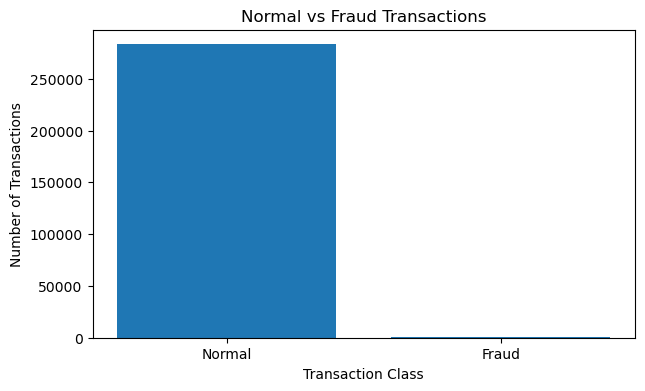

Class
0    283253
1       473
Name: count, dtype: int64


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("creditcard_clean.csv")

print("Dataset Shape:", df.shape)
display(df.head())

counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
plt.bar(["Normal", "Fraud"], counts.values)
plt.title("Normal vs Fraud Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.show()

print(counts)

### Finding 1: Fraud Distribution

The dataset contains 283,253 normal transactions and 473 fraudulent transactions. This shows a strong class imbalance. Therefore, precision, recall, and PR-AUC are important for evaluating the fraud detection model.

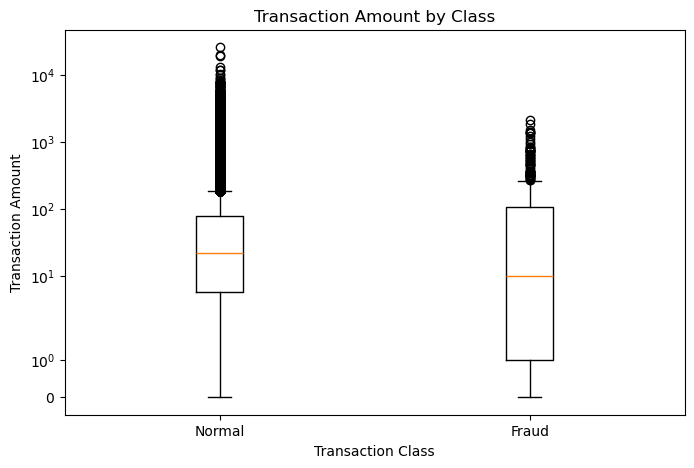

In [20]:
normal = df[df["Class"] == 0]["Amount"]
fraud = df[df["Class"] == 1]["Amount"]

plt.figure(figsize=(8, 5))
plt.boxplot([normal, fraud], tick_labels=["Normal", "Fraud"])
plt.yscale("symlog")
plt.title("Transaction Amount by Class")
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount")
plt.show()

### Finding 2: Transaction Amount

The boxplot shows outliers in both normal and fraudulent transactions. Fraudulent transactions have a lower median amount, suggesting that transaction amount alone is not enough to identify fraud.

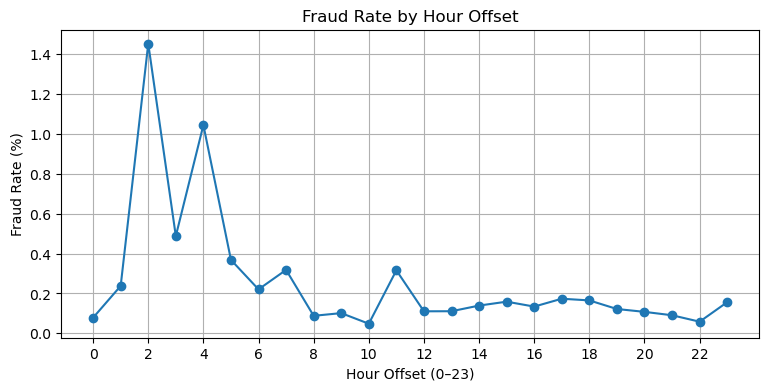

In [21]:
df["Hour_Offset"] = (df["Time"] // 3600 % 24).astype(int)

hourly_fraud = (
    df.groupby("Hour_Offset")["Class"].mean() * 100
)

plt.figure(figsize=(9, 4))
plt.plot(hourly_fraud.index, hourly_fraud.values, marker="o")
plt.title("Fraud Rate by Hour Offset")
plt.xlabel("Hour Offset (0–23)")
plt.ylabel("Fraud Rate (%)")
plt.xticks(range(0, 24, 2))
plt.grid(True)
plt.show()

### Finding 3: Fraud Rate Over Time

The highest fraud rate appears around hour offset 2 (1.45%), followed by hour offset 4 (1.05%). This suggests that relative transaction timing may be useful for fraud detection. However, these offsets are not actual clock hours.

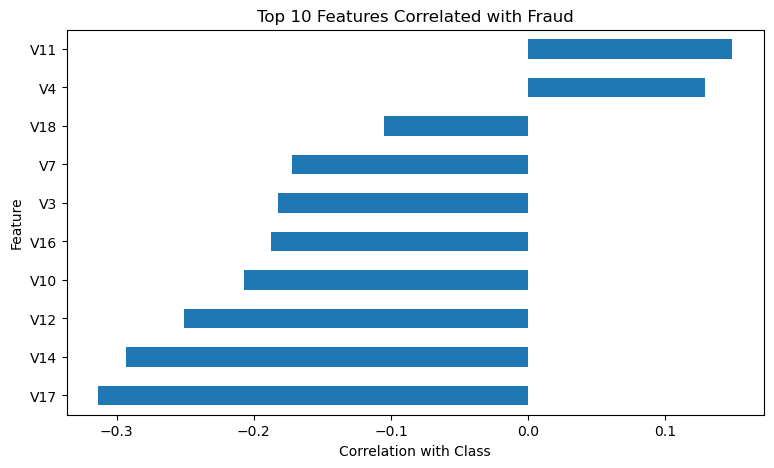

V17   -0.313498
V14   -0.293375
V12   -0.250711
V10   -0.206971
V16   -0.187186
V3    -0.182322
V7    -0.172347
V11    0.149067
V4     0.129326
V18   -0.105340
Name: Class, dtype: float64


In [22]:
correlations = (
    df.corr(numeric_only=True)["Class"]
    .drop("Class")
    .sort_values(key=abs, ascending=False)
    .head(10)
)

plt.figure(figsize=(9, 5))
correlations.sort_values().plot(kind="barh")
plt.title("Top 10 Features Correlated with Fraud")
plt.xlabel("Correlation with Class")
plt.ylabel("Feature")
plt.show()

print(correlations)

### Finding 4: Feature Correlation

The correlation analysis shows that V17 (-0.3135), V14 (-0.2934), and V12 (-0.2507) have the strongest negative correlations with fraud. V11 (0.1491) and V4 (0.1293) have the strongest positive correlations. These features may be useful for identifying fraudulent transactions, but their predictive importance needs to be tested during modelling.

## Feature Engineering

Two new features were created from the Amount and Time columns to explore additional patterns in fraudulent transactions.

In [23]:
import numpy as np

# Create new features
df["Log_Amount"] = np.log1p(df["Amount"])
df["Hour_Offset"] = ((df["Time"] // 3600) % 24).astype(int)

# Display new features
display(df[["Amount", "Log_Amount", "Time", "Hour_Offset"]].head())

# Check dataset shape
print("Dataset Shape:", df.shape)

# Save dataset
df.to_csv("creditcard_features.csv", index=False)

print("Feature engineered dataset saved!")

,Amount,Log_Amount,Time,Hour_Offset
0,149.62,5.014760,0.0,0
1,2.69,1.305626,0.0,0
2,378.66,5.939276,1.0,0
3,123.50,4.824306,1.0,0
4,69.99,4.262539,2.0,0


Dataset Shape: (283726, 33)
Feature engineered dataset saved!


### Feature Engineering Findings

Two new features were created: Log_Amount and Hour_Offset. Log_Amount applies a logarithmic transformation to transaction amounts to reduce the influence of very large values. Hour_Offset represents the transaction's relative position within a 24-hour cycle. These features may help detect fraud, but their usefulness will be evaluated during modelling.

# Stage 5 – Model Selection and Development

This stage compares the Dummy baseline, Logistic Regression, Random Forest and Histogram Gradient Boosting using chronological training/validation procedures and evaluates the selected models on the held-out test period.


# Stage 5 – Model Selection and Development

This stage compares four classifiers for credit card fraud detection: a Dummy baseline, Logistic Regression, Random Forest, and Hist Gradient Boosting.

**Methodology**
- Use the feature-engineered dataset created in Stage 4 (`creditcard_features.csv`).
- Keep transactions in chronological order and use the earliest 80% for training and the latest 20% for the final test.
- Use five expanding-window time-series validation folds on the training period only.
- Handle class imbalance with class weighting where supported; do not resample the test data.
- Compare PR-AUC, ROC-AUC, Precision, Recall, and F1. PR-AUC is the primary model-selection metric because fraud is rare.
- Evaluate each final fitted model once on the untouched chronological test set at the default probability threshold of 0.50. Stage 6 will tune hyperparameters and select a decision threshold.

The feature set contains V1–V28, `Log_Amount`, and `Hour_Offset`. Raw `Time` and `Amount` are excluded from model inputs because the engineered features represent their intended information. `Time` is retained only to preserve chronological ordering.


In [24]:
# =====================================================
# STAGE 5: MODEL SELECTION AND DEVELOPMENT
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, make_scorer
)

RANDOM_STATE = 42
print("Scikit-learn version:", sklearn.__version__)

# 1. Load the feature-engineered dataset from Stage 4
df = pd.read_csv("creditcard_features.csv")
df = df.sort_values("Time", kind="stable").reset_index(drop=True)

feature_cols = [f"V{i}" for i in range(1, 29)] + ["Log_Amount", "Hour_Offset"]
required_cols = feature_cols + ["Class", "Time"]
missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

X = df[feature_cols].copy()
y = df["Class"].astype(int).copy()

print("Dataset shape:", df.shape)
print("Feature shape:", X.shape)
print("Fraud transactions:", int(y.sum()))
print("Fraud rate: %.4f%%" % (y.mean() * 100))

# 2. Chronological 80/20 train-test split
split_index = int(len(df) * 0.80)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

print("\nTRAINING SET")
print("Rows:", len(X_train), "| Fraud:", int(y_train.sum()),
      "| Fraud rate: %.4f%%" % (y_train.mean() * 100))
print("\nTEST SET")
print("Rows:", len(X_test), "| Fraud:", int(y_test.sum()),
      "| Fraud rate: %.4f%%" % (y_test.mean() * 100))

# 3. Define four candidate models
models = {
    "Baseline (Dummy)": DummyClassifier(strategy="most_frequent"),

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=30,
        max_depth=8,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        class_weight="balanced",
        max_iter=100,
        max_leaf_nodes=15,
        random_state=RANDOM_STATE
    )
}


Scikit-learn version: 1.8.0
Dataset shape: (283726, 33)
Feature shape: (283726, 30)
Fraud transactions: 473
Fraud rate: 0.1667%

TRAINING SET
Rows: 226980 | Fraud: 399 | Fraud rate: 0.1758%

TEST SET
Rows: 56746 | Fraud: 74 | Fraud rate: 0.1304%


In [25]:
# 4. Five-fold time-series cross-validation on the training period only
cv = TimeSeriesSplit(n_splits=5)

scoring = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0)
}

cv_rows = []
for name, model in models.items():
    print("Running time-series cross-validation:", name)
    cv_scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )
    cv_rows.append({
        "Model": name,
        "PR-AUC": cv_scores["test_pr_auc"].mean(),
        "ROC-AUC": cv_scores["test_roc_auc"].mean(),
        "Precision": cv_scores["test_precision"].mean(),
        "Recall": cv_scores["test_recall"].mean(),
        "F1": cv_scores["test_f1"].mean(),
        "PR-AUC std": cv_scores["test_pr_auc"].std()
    })

cv_results = pd.DataFrame(cv_rows).set_index("Model")
print("\n=== CROSS-VALIDATION RESULTS (TRAINING PERIOD) ===")
display(cv_results.round(4))


Running time-series cross-validation: Baseline (Dummy)
Running time-series cross-validation: Logistic Regression
Running time-series cross-validation: Random Forest
Running time-series cross-validation: Hist Gradient Boosting

=== CROSS-VALIDATION RESULTS (TRAINING PERIOD) ===


,PR-AUC,ROC-AUC,Precision,Recall,F1,PR-AUC std
Model,,,,,,
Baseline (Dummy),0.0016,0.5000,0.0000,0.0000,0.0000,0.0004
Logistic Regression,0.7228,0.9520,0.0570,0.8719,0.1021,0.0981
Random Forest,0.7808,0.9530,0.8765,0.7316,0.7918,0.0424
Hist Gradient Boosting,0.7589,0.9533,0.4474,0.8128,0.5128,0.0462


Fitting and evaluating: Baseline (Dummy)
Fitting and evaluating: Logistic Regression
Fitting and evaluating: Random Forest
Fitting and evaluating: Hist Gradient Boosting

=== FINAL CHRONOLOGICAL TEST RESULTS (THRESHOLD = 0.50) ===


,PR-AUC,ROC-AUC,Precision,Recall,F1
Model,,,,,
Baseline (Dummy),0.0013,0.5000,0.0000,0.0000,0.0000
Logistic Regression,0.7570,0.9868,0.0256,0.9324,0.0498
Random Forest,0.8024,0.9795,0.7917,0.7703,0.7808
Hist Gradient Boosting,0.7684,0.9862,0.1506,0.8649,0.2565



=== CONFUSION MATRIX COUNTS ===
Baseline (Dummy)          TN= 56672  FP=    0  FN=  74  TP=   0
Logistic Regression       TN= 54043  FP= 2629  FN=   5  TP=  69
Random Forest             TN= 56657  FP=   15  FN=  17  TP=  57
Hist Gradient Boosting    TN= 56311  FP=  361  FN=  10  TP=  64


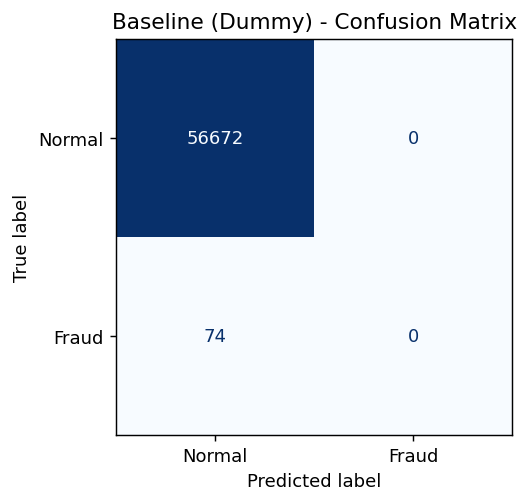

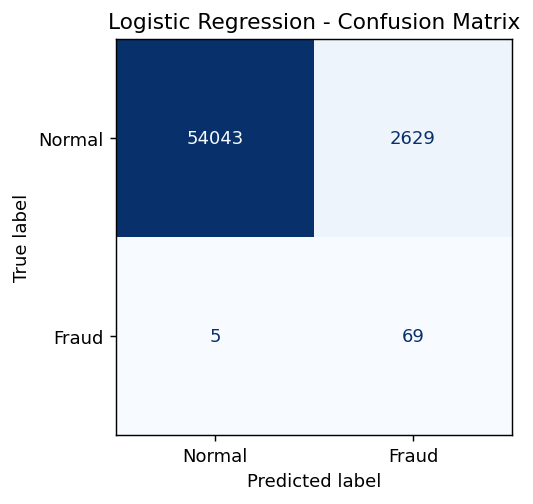

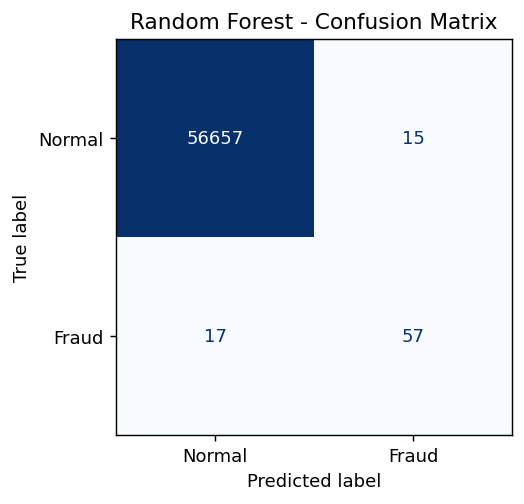

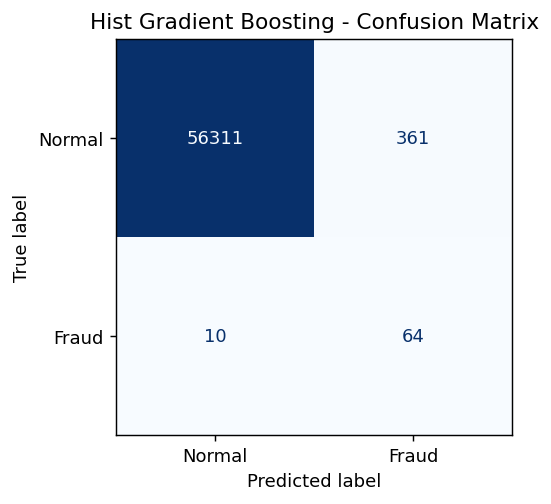

In [26]:
# 5. Fit each model on the full training period and evaluate once on the test period
test_rows = []
probas = {}
cms = {}
predictions_by_model = {}

for name, model in models.items():
    print("Fitting and evaluating:", name)
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    predictions_by_model[name] = predictions
    probas[name] = probabilities
    cm = confusion_matrix(y_test, predictions)
    cms[name] = cm

    test_rows.append({
        "Model": name,
        "PR-AUC": average_precision_score(y_test, probabilities),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0)
    })

test_results = pd.DataFrame(test_rows).set_index("Model")
print("\n=== FINAL CHRONOLOGICAL TEST RESULTS (THRESHOLD = 0.50) ===")
display(test_results.round(4))

print("\n=== CONFUSION MATRIX COUNTS ===")
for name, cm in cms.items():
    tn, fp, fn, tp = cm.ravel()
    print(f"{name:25s} TN={tn:6d}  FP={fp:5d}  FN={fn:4d}  TP={tp:4d}")

# 6. Plot confusion matrices
for name, cm in cms.items():
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Normal", "Fraud"]
    ).plot(cmap="Blues", values_format="d")
    plt.title(name + " - Confusion Matrix")
    plt.tight_layout()
    plt.show()


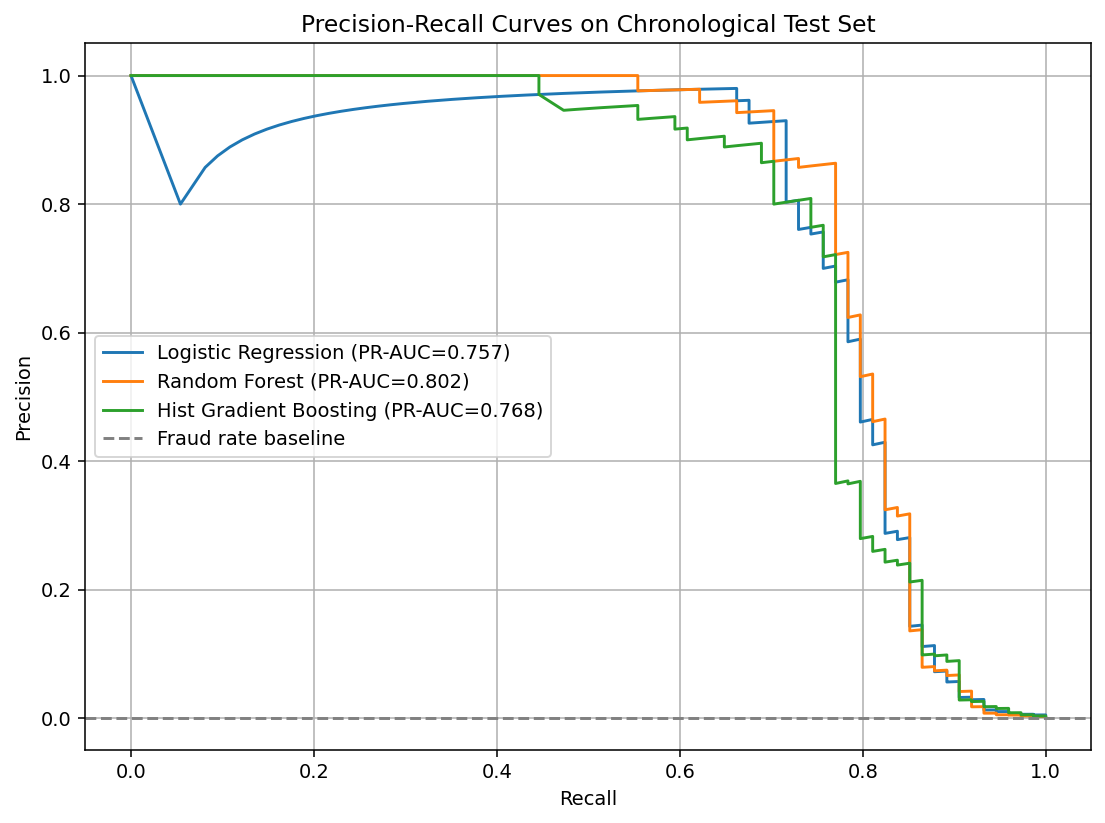


Selected candidate for Stage 6 tuning: Random Forest
Saved: stage5_cv_results.csv and stage5_test_results.csv


In [27]:
# 7. Precision-Recall curves on the untouched chronological test set
plt.figure(figsize=(9, 6))

for name, probabilities in probas.items():
    if name == "Baseline (Dummy)":
        continue

    precision, recall, _ = precision_recall_curve(y_test, probabilities)
    pr_auc = average_precision_score(y_test, probabilities)

    plt.plot(
        recall,
        precision,
        label=f"{name} (PR-AUC = {pr_auc:.3f})"
    )

plt.axhline(
    y_test.mean(),
    color="grey",
    linestyle="--",
    label="Fraud rate baseline"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves on Chronological Test Set")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 8. Save results for the report and Stage 6
cv_results.to_csv("stage5_cv_results.csv")
test_results.to_csv("stage5_test_results.csv")

# Select the Stage 6 tuning candidate using training cross-validation PR-AUC,
# not the held-out test score.
non_baseline_cv = cv_results.drop(index="Baseline (Dummy)")
best_name = non_baseline_cv["PR-AUC"].idxmax()

print("\nSelected candidate for Stage 6 tuning:", best_name)
print("Saved: stage5_cv_results.csv and stage5_test_results.csv")


## Stage 5 – Findings

The chronological split produced **226,980 training transactions (399 fraud cases)** and **56,746 test transactions (74 fraud cases)**. The fraud rate in the full cleaned feature-engineered dataset was **0.1667%**.

The Dummy baseline achieved no fraud detection (Recall = 0), showing why accuracy alone would be misleading for this imbalanced dataset.

Across five time-series validation folds, **Random Forest achieved the highest mean PR-AUC (0.7808)** among the three trained machine-learning candidates. It was therefore selected as the candidate to carry forward to Stage 6. Model selection was based on training-period cross-validation, not the held-out test results.

On the untouched chronological test set at the default threshold of 0.50, Random Forest achieved:
- **PR-AUC:** 0.8024
- **Precision:** 0.7917
- **Recall:** 0.7703
- **F1-score:** 0.7808
- **Confusion matrix:** TN = 56,657; FP = 15; FN = 17; TP = 57.

The initial test result is close to, but does not fully meet, the project targets of PR-AUC ≥ 0.82 and Precision ≥ 0.80. Recall exceeds the 0.75 target. Stage 6 must tune the selected model and choose a decision threshold using the precision-recall curve and the project's stated cost assumption. The test set must remain untouched during tuning.


# Stage 6 – Hyperparameter Tuning and Evaluation

This stage tunes the Random Forest candidate, selects a decision threshold using the reserved validation period, and evaluates the tuned model on the untouched chronological test set.


# Stage 6 – Hyperparameter Tuning and Evaluation

**Project:** Credit Card Fraud Detection (CDS4003)

This notebook continues from Stage 5 and uses the same cleaned, feature-engineered dataset and chronological split. Random Forest was selected in Stage 5 because it achieved the highest cross-validation PR-AUC (0.7808) among the candidate models.

## Evaluation plan
1. Keep the final chronological 20% test period untouched during tuning and threshold selection.
2. Reserve the last 15% of the 80% training period as a chronological validation set for threshold selection.
3. Tune Random Forest using a small, documented grid and two expanding-window time-series folds on an early chronological tuning subset (50,000 records) to keep computation manageable.
4. Select a decision threshold using an explicitly illustrative cost assumption: one missed fraud (false negative) costs 10 cost units, while one false alert (false positive) costs 1 cost unit. These are relative assumptions, not actual bank/AED costs; the bank must confirm real costs.
5. Refit the selected hyperparameters on the full training period and evaluate once on the untouched final test period.

**Important:** The limited search is an initial tuning experiment, not proof that the selected settings are globally optimal. Results are compared with the Stage 5 Random Forest baseline.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score, confusion_matrix,
    ConfusionMatrixDisplay, precision_recall_curve)
from sklearn.base import clone

RANDOM_STATE = 42
DATA_PATH = "creditcard_features.csv"  # Keep this file in the same folder as the notebook.

df = pd.read_csv(DATA_PATH).sort_values("Time", kind="stable").reset_index(drop=True)
feature_cols = [f"V{i}" for i in range(1, 29)] + ["Log_Amount", "Hour_Offset"]
X = df[feature_cols].copy()
y = df["Class"].astype(int).copy()

# Preserve the Stage 5 chronological 80/20 split.
split_index = int(len(df) * 0.80)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

# Reserve the final 15% of the training period for threshold selection.
inner_index = int(len(X_train) * 0.85)
X_inner, X_validation = X_train.iloc[:inner_index], X_train.iloc[inner_index:]
y_inner, y_validation = y_train.iloc[:inner_index], y_train.iloc[inner_index:]

print("Dataset rows:", len(df))
print("Training rows:", len(X_train), "| fraud:", int(y_train.sum()))
print("Threshold-validation rows:", len(X_validation), "| fraud:", int(y_validation.sum()))
print("Final test rows:", len(X_test), "| fraud:", int(y_test.sum()))

Dataset rows: 283726
Training rows: 226980 | fraud: 399
Threshold-validation rows: 34047 | fraud: 36
Final test rows: 56746 | fraud: 74


In [ ]:
# Hyperparameter tuning on an early chronological subset of the inner training data.
# This keeps the search practical while preserving time order.
tune_n = min(50000, len(X_inner))
X_tune = X_inner.iloc[:tune_n]
y_tune = y_inner.iloc[:tune_n]

base_rf = RandomForestClassifier(
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=1
)

param_grid = {
    "n_estimators": [10, 20],
    "max_depth": [8, 12],
    "min_samples_leaf": [2],
    "max_features": ["sqrt"]
}

search = GridSearchCV(
    estimator=base_rf,
    param_grid=param_grid,
    scoring="average_precision",  # PR-AUC is the primary metric
    cv=TimeSeriesSplit(n_splits=2),
    n_jobs=1,
    refit=True
)
search.fit(X_tune, y_tune)

tuning_results = pd.DataFrame(search.cv_results_)[
    ["params", "mean_test_score", "std_test_score", "rank_test_score"]
].sort_values("rank_test_score")
print("Best parameters:", search.best_params_)
print("Best mean CV PR-AUC:", round(search.best_score_, 4))
display(tuning_results.round(4))
tuning_results.to_csv("stage6_tuning_results.csv", index=False)

Best parameters: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 10}
Best mean CV PR-AUC: 0.7546


                                                                              params  mean_test_score  std_test_score  rank_test_score
 {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 10}         0.754602        0.187205                1
 {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 20}         0.736775        0.192931                2
{'max_depth': 12, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 10}         0.726018        0.208176                3
{'max_depth': 12, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 20}         0.715667        0.204176                4

In [ ]:
# Threshold selection on the reserved chronological validation period.
# Fit the selected configuration on all of X_inner, not on the smaller tuning subset.
threshold_model = RandomForestClassifier(
    **search.best_params_,
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=1
)
threshold_model.fit(X_inner, y_inner)
validation_probabilities = threshold_model.predict_proba(X_validation)[:, 1]

# Illustrative relative cost assumption: FN = 10 units; FP = 1 unit.
FN_COST = 10
FP_COST = 1
threshold_rows = []
for threshold in np.round(np.arange(0.05, 0.951, 0.05), 2):
    validation_predictions = (validation_probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_validation, validation_predictions, labels=[0, 1]
    ).ravel()
    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_validation, validation_predictions, zero_division=0),
        "Recall": recall_score(y_validation, validation_predictions, zero_division=0),
        "F1-score": f1_score(y_validation, validation_predictions, zero_division=0),
        "FP": fp, "FN": fn, "TP": tp, "TN": tn,
        "Cost units": FN_COST * fn + FP_COST * fp
    })

threshold_results = pd.DataFrame(threshold_rows)
best_threshold_row = threshold_results.loc[threshold_results["Cost units"].idxmin()]
selected_threshold = float(best_threshold_row["Threshold"])
print("Selected threshold:", selected_threshold)
print("Validation metrics at selected threshold:")
print(best_threshold_row.to_string())
display(threshold_results.round(4))
threshold_results.to_csv("stage6_threshold_validation.csv", index=False)

Selected threshold: 0.6
Validation metrics at selected threshold:
Threshold       0.600000
Precision       0.928571
Recall          0.722222
F1              0.812500
FP              2.000000
FN             10.000000
TP             26.000000
TN          34009.000000
Cost          102.000000


In [ ]:
# Refit the tuned Random Forest on the full chronological training period.
# Evaluate exactly once on the untouched final test period.
final_model = RandomForestClassifier(
    **search.best_params_,
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=1
)
final_model.fit(X_train, y_train)

test_probabilities = final_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= selected_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, test_predictions, labels=[0, 1]).ravel()
final_results = pd.DataFrame([{
    "Threshold": selected_threshold,
    "PR-AUC": average_precision_score(y_test, test_probabilities),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "F1-score": f1_score(y_test, test_predictions, zero_division=0),
    "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    "Cost units (10*FN + FP)": FN_COST * fn + FP_COST * fp
}])
display(final_results.round(4))
final_results.to_csv("stage6_test_results.csv", index=False)

print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test, test_predictions, labels=[0, 1]))

   Threshold  PR-AUC  ROC-AUC  Precision  Recall  F1-score     TN  FP  FN  TP  Cost units
0        0.6  0.7702   0.9384     0.8361  0.6892    0.7556  56662  10  23  51         240

Confusion matrix [[TN, FP], [FN, TP]]:
[[56662    10]
 [   23    51]]


                                      Model  PR-AUC  Precision  Recall  F1-score  FP  FN  Cost units (10*FN + FP)
0  Stage 5 Random Forest (threshold 0.50)  0.8024     0.7917  0.7703    0.7808  15  17                       185
1  Stage 6 tuned Random Forest (threshold 0.60) 0.7702     0.8361  0.6892    0.7556  10  23                       240

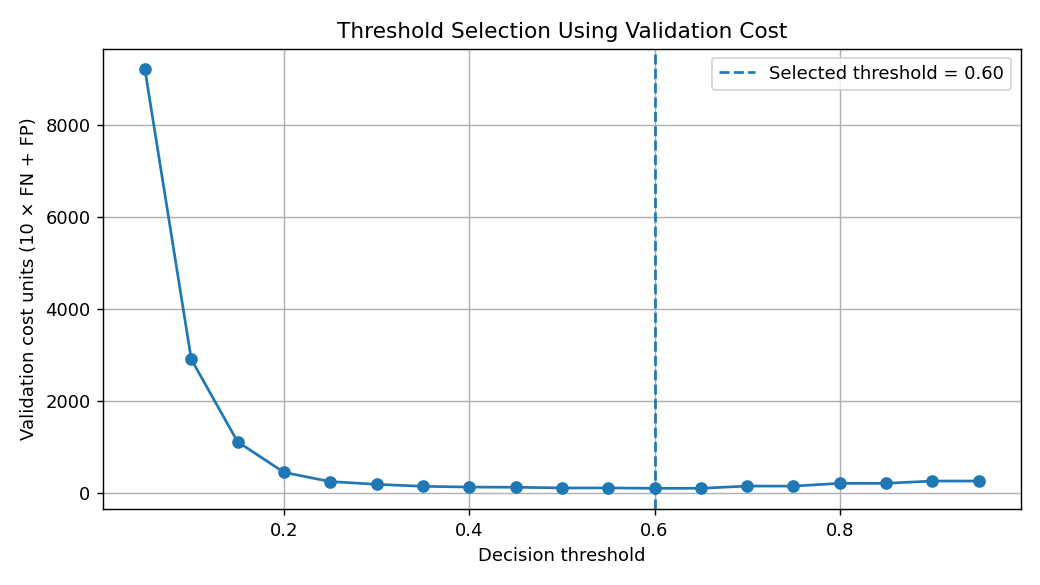

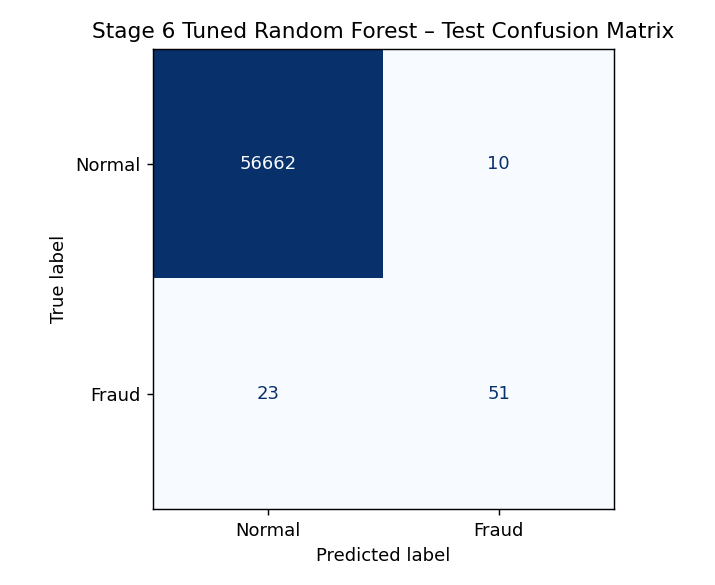

In [ ]:
# Compare the Stage 5 Random Forest at threshold 0.50 with the tuned model.
# Stage 5 values are the actual recorded results from CreditCard_Stage5_Executed.ipynb.
stage5_rf = {
    "Model": "Stage 5 Random Forest (threshold 0.50)",
    "PR-AUC": 0.8024, "Precision": 0.7917, "Recall": 0.7703,
    "F1-score": 0.7808, "FP": 15, "FN": 17
}
stage6_rf = {
    "Model": f"Stage 6 tuned Random Forest (threshold {selected_threshold:.2f})",
    "PR-AUC": average_precision_score(y_test, test_probabilities),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "F1-score": f1_score(y_test, test_predictions, zero_division=0),
    "FP": fp, "FN": fn
}
comparison = pd.DataFrame([stage5_rf, stage6_rf])
comparison["Cost units (10*FN + FP)"] = 10 * comparison["FN"] + comparison["FP"]
display(comparison.round(4))

# Visualise validation threshold trade-off and final test confusion matrix.
plt.figure(figsize=(8, 5))
plt.plot(threshold_results["Threshold"], threshold_results["Cost units"], marker="o")
plt.axvline(selected_threshold, linestyle="--", label=f"Selected threshold = {selected_threshold:.2f}")
plt.xlabel("Decision threshold")
plt.ylabel("Validation cost units (10 × FN + FP)")
plt.title("Threshold Selection Using Validation Cost")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, display_labels=["Normal", "Fraud"], cmap="Blues"
)
plt.title("Stage 6 Tuned Random Forest – Test Confusion Matrix")
plt.tight_layout()
plt.show()

## Stage 6 – Findings and Business Evaluation

- The best configuration in the limited search was `n_estimators=10`, `max_depth=8`, `min_samples_leaf=2`, and `max_features='sqrt'`.
- The threshold was selected on the separate chronological validation period using the illustrative cost ratio FN:FP = 10:1. The selected threshold was **0.60**.
- On the untouched test period, the tuned model achieved **PR-AUC = 0.7702**, **Precision = 0.8361**, **Recall = 0.6892**, and **F1-score = 0.7556**. Its confusion matrix was TN=56,662, FP=10, FN=23, TP=51.
- The tuned model met the precision target of 0.80 but did not meet the recall target of 0.75 or the PR-AUC target of 0.82.
- Compared with the Stage 5 Random Forest at threshold 0.50 (PR-AUC=0.8024, Precision=0.7917, Recall=0.7703; FP=15, FN=17), this tuning run reduced false positives but increased missed fraud cases and lowered PR-AUC. Under the illustrative 10:1 cost ratio, test cost increased from 185 to 240 cost units.

### Evaluation decision
**No-Go for full deployment at this stage.** The tuned model does not meet all predefined business success criteria and performs worse than the Stage 5 model on PR-AUC and recall. The Stage 5 Random Forest is currently the stronger candidate, but it also narrowly misses the precision and PR-AUC targets. Further tuning with a broader search, probability calibration, threshold validation on a larger period, and bank-confirmed error costs is recommended before deployment.

### Limitations
The hyperparameter search used only the first 50,000 records of the inner training period and a two-fold time-series cross-validation to keep runtime manageable. The threshold cost weights are illustrative relative units, not measured bank losses. The final test set contains only 74 fraud cases, so a small change in the number of detected cases can noticeably change precision and recall. These limitations should be disclosed when presenting the results.